<a href="https://colab.research.google.com/github/chadowsv/model-loa/blob/main/04_Modelos_ML/LSTM/LSTM_V1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelo LSTM para predicción de homicidios

## ¿Qué hará este notebook?

Construiremos **dos modelos LSTM**, usando únicamente el enfoque LSTM:

1. **Regresión:** predecir cuántos homicidios habrá (`total_homicidios`).
2. **Clasificación:** predecir si habrá homicidios (`hubo_homicidios`: 0 = no, 1 = sí).

La unidad de análisis será **provincia–distrito–día**. Para cada día, el modelo observará los **28 días anteriores** y predecirá el día siguiente.

### Fechas de evaluación
- Subentrenamiento: objetivos anteriores al 01-01-2023.
- Validación: objetivos de 2023 y 2024.
- Prueba: objetivos desde el 01-01-2025.

**Importante:** no rellenamos días ausentes con cero, porque un día sin registro podría significar falta de cobertura y no ausencia de homicidios. Las ventanas que atraviesan fechas ausentes se descartan.

Este notebook conserva el CSV y la ruta de Google Drive del notebook que compartiste. No contiene AdaBoost ni otros algoritmos.

## 1. Instalar e importar las librerías

**¿Qué hacemos?** Instalamos TensorFlow, que contiene las herramientas para construir y entrenar redes neuronales. También importamos pandas y NumPy para preparar los datos, y scikit-learn para escalar variables y calcular métricas.

In [2]:
%pip install -q tensorflow

In [3]:
import gc
import json
import time
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix, classification_report
)

from tensorflow import keras
from tensorflow.keras import layers

SEMILLA = 42
np.random.seed(SEMILLA)
tf.keras.utils.set_random_seed(SEMILLA)

print('TensorFlow:', tf.__version__)
print('Dispositivos:', tf.config.list_physical_devices())

TensorFlow: 2.21.0
Dispositivos: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2. Conectar Google Drive y definir las rutas

**¿Qué hacemos?** Conectamos Colab con Drive para leer el mismo CSV procesado que utilizaste en el notebook anterior. También creamos una carpeta donde se guardarán los modelos y resultados.

Si tu archivo está en la misma ubicación que en el notebook original, no necesitas cambiar la ruta.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

ARCHIVO_DATOS = Path(
    '/content/drive/MyDrive/ModelLOA/Datos_Procesados/dataset_homicidios_final.csv'
)
CARPETA_RESULTADOS = Path(
    '/content/drive/MyDrive/ModelLOA/Resultados/LSTM_Semana6'
)
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)

if not ARCHIVO_DATOS.is_file():
    raise FileNotFoundError(
        f'No se encontró el CSV: {ARCHIVO_DATOS}. Revisa la ruta en Google Drive.'
    )

print('Archivo de entrada:', ARCHIVO_DATOS)
print('Carpeta de resultados:', CARPETA_RESULTADOS)

Mounted at /content/drive
Archivo de entrada: /content/drive/MyDrive/ModelLOA/Datos_Procesados/dataset_homicidios_final.csv
Carpeta de resultados: /content/drive/MyDrive/ModelLOA/Resultados/LSTM_Semana6


## 3. Cargar y revisar el dataset

**¿Qué hacemos?** Leemos el CSV y comprobamos que tenga las columnas necesarias. Conservamos los códigos de provincia y distrito como texto para no perder ceros a la izquierda.

El objetivo de regresión es `total_homicidios`. El objetivo de clasificación se crea a partir de ese conteo: si es mayor que cero, la clase será 1; de lo contrario, será 0.

In [5]:
COLUMNAS_EXIGIDAS = [
    'fecha', 'codigo_provincia', 'codigo_distrito', 'franja_horaria',
    'es_feriado', 'total_homicidios'
]
TARGET_REG = 'total_homicidios'
TARGET_CLF = 'hubo_homicidios'

DF = pd.read_csv(
    ARCHIVO_DATOS,
    encoding='utf-8-sig',
    dtype={
        'codigo_provincia': 'string',
        'codigo_distrito': 'string',
        'franja_horaria': 'string'
    },
    low_memory=False
)

faltantes = sorted(set(COLUMNAS_EXIGIDAS) - set(DF.columns))
if faltantes:
    raise ValueError(f'Faltan columnas en el CSV: {faltantes}')

# El archivo original utiliza el formato día/mes/año.
DF['fecha'] = pd.to_datetime(
    DF['fecha'], format='%d/%m/%Y', errors='coerce'
)
if DF['fecha'].isna().any():
    raise ValueError('Hay fechas inválidas o vacías en el CSV.')

for col in ['codigo_provincia', 'codigo_distrito', 'franja_horaria']:
    DF[col] = DF[col].str.strip()
    if DF[col].isna().any() or DF[col].eq('').any():
        raise ValueError(f'Hay códigos o categorías vacías en {col}.')

DF['es_feriado'] = (
    DF['es_feriado'].astype('string').str.lower().map({
        'true': 1, 'false': 0, '1': 1, '0': 0
    })
)
DF[TARGET_REG] = pd.to_numeric(DF[TARGET_REG], errors='coerce')

if DF[['es_feriado', TARGET_REG]].isna().any().any():
    raise ValueError('Hay valores nulos o no numéricos en feriado/conteo.')
if (DF[TARGET_REG] < 0).any():
    raise ValueError('El conteo de homicidios no puede ser negativo.')

CLAVE_ORIGINAL = [
    'codigo_provincia', 'codigo_distrito', 'fecha', 'franja_horaria'
]
if DF.duplicated(CLAVE_ORIGINAL).any():
    raise ValueError('Hay filas duplicadas para provincia-distrito-fecha-franja.')

DF[TARGET_REG] = DF[TARGET_REG].astype('float32')
DF['es_feriado'] = DF['es_feriado'].astype('int8')
DF[TARGET_CLF] = (DF[TARGET_REG] > 0).astype('int8')

print('Filas originales:', f'{len(DF):,}')
print('Periodo:', DF['fecha'].min().date(), 'a', DF['fecha'].max().date())
print('Provincias:', DF['codigo_provincia'].nunique())
print('Distritos:', DF[['codigo_provincia','codigo_distrito']].drop_duplicates().shape[0])
display(DF.head())

Filas originales: 2,590,560
Periodo: 2014-01-01 a 2026-08-31
Provincias: 24
Distritos: 140


,codigo_provincia,codigo_distrito,fecha,franja_horaria,total_homicidios,nombre_feriado,es_feriado,anio,mes,dia_semana_num,dia_semana,categoria_incidencia,hubo_homicidios
0,01,01D01,2014-01-01,madrugada,1.0,Año Nuevo,1,2014,1,2,Miercoles,media,1
1,01,01D01,2014-01-01,manana,0.0,Año Nuevo,1,2014,1,2,Miercoles,baja,0
2,01,01D01,2014-01-01,noche,0.0,Año Nuevo,1,2014,1,2,Miercoles,baja,0
3,01,01D01,2014-01-01,tarde,0.0,Año Nuevo,1,2014,1,2,Miercoles,baja,0
4,01,01D01,2014-01-02,madrugada,0.0,NO_FERIADO,0,2014,1,3,Jueves,baja,0


## 4. Convertir los datos a frecuencia diaria

**¿Qué hacemos?** El CSV tiene registros separados por franja horaria. Para una predicción diaria, sumamos las franjas del mismo distrito y fecha.

La agrupación se realiza por **provincia, distrito y fecha**. Esto evita mezclar distritos que pudieran tener el mismo código en provincias diferentes.

No agregamos filas para días que no aparecen en los datos. Primero necesitamos comprobar que existan 29 fechas consecutivas para crear una ventana: 28 días de historia y el día que queremos predecir.

In [6]:
CLAVES_ENTIDAD = ['codigo_provincia', 'codigo_distrito']
CLAVE_DIARIA = CLAVES_ENTIDAD + ['fecha']

DF_DIA = (
    DF.groupby(CLAVE_DIARIA, as_index=False, sort=False)
      .agg(
          total_homicidios=(TARGET_REG, 'sum'),
          es_feriado=('es_feriado', 'max')
      )
)

del DF
gc.collect()

DF_DIA[TARGET_REG] = DF_DIA[TARGET_REG].astype('float32')
DF_DIA[TARGET_CLF] = (DF_DIA[TARGET_REG] > 0).astype('int8')
DF_DIA = DF_DIA.sort_values(CLAVE_DIARIA).reset_index(drop=True)

print('Registros diarios:', f'{len(DF_DIA):,}')
print('Entidades provincia-distrito:',
      DF_DIA[CLAVES_ENTIDAD].drop_duplicates().shape[0])
display(DF_DIA.head())

Registros diarios: 647,640
Entidades provincia-distrito: 140


,codigo_provincia,codigo_distrito,fecha,total_homicidios,es_feriado,hubo_homicidios
0,01,01D01,2014-01-01,1.0,1,1
1,01,01D01,2014-01-02,0.0,0,0
2,01,01D01,2014-01-03,0.0,0,0
3,01,01D01,2014-01-04,0.0,0,0
4,01,01D01,2014-01-05,0.0,0,0


## 5. Crear variables de calendario

**¿Qué hacemos?** Incorporamos información que puede conocerse antes de que ocurra el día que queremos predecir:

- Día de la semana.
- Mes.
- Si es fin de semana.
- Si es feriado.

El día de la semana y el mes se representan con seno y coseno. Esta transformación circular permite que el modelo entienda, por ejemplo, que domingo y lunes son días cercanos en el calendario.

In [7]:
DF_DIA['dia_semana_num'] = DF_DIA['fecha'].dt.dayofweek
DF_DIA['mes'] = DF_DIA['fecha'].dt.month

DF_DIA['es_fin_semana'] = (
    DF_DIA['dia_semana_num'].isin([5, 6])
).astype('int8')

DF_DIA['dia_sin'] = np.sin(
    2 * np.pi * DF_DIA['dia_semana_num'] / 7
).astype('float32')
DF_DIA['dia_cos'] = np.cos(
    2 * np.pi * DF_DIA['dia_semana_num'] / 7
).astype('float32')

DF_DIA['mes_sin'] = np.sin(
    2 * np.pi * (DF_DIA['mes'] - 1) / 12
).astype('float32')
DF_DIA['mes_cos'] = np.cos(
    2 * np.pi * (DF_DIA['mes'] - 1) / 12
).astype('float32')

display(DF_DIA[
    ['fecha', 'dia_semana_num', 'es_fin_semana', 'mes',
     'es_feriado', 'dia_sin', 'dia_cos', 'mes_sin', 'mes_cos']
].head())

,fecha,dia_semana_num,es_fin_semana,mes,es_feriado,dia_sin,dia_cos,mes_sin,mes_cos
0,2014-01-01,2,0,1,1,0.974928,-0.222521,0.0,1.0
1,2014-01-02,3,0,1,0,0.433884,-0.900969,0.0,1.0
2,2014-01-03,4,0,1,0,-0.433884,-0.900969,0.0,1.0
3,2014-01-04,5,1,1,0,-0.974928,-0.222521,0.0,1.0
4,2014-01-05,6,1,1,0,-0.781832,0.623490,0.0,1.0


## 6. Definir los periodos de entrenamiento, validación y prueba

**¿Qué hacemos?** Separamos cronológicamente los días que queremos predecir. No mezclamos fechas al azar, porque el objetivo es simular una predicción del futuro usando información del pasado.

- Entrenamiento inicial: antes de 2023.
- Validación: 2023 y 2024.
- Prueba: desde 2025.

La fecha que determina el conjunto es el **día objetivo**, no el primer día de la ventana histórica.

In [8]:
FECHA_VALIDACION = pd.Timestamp('2023-01-01')
FECHA_TEST = pd.Timestamp('2025-01-01')

for nombre, mascara in [
    ('Antes de 2023', DF_DIA['fecha'] < FECHA_VALIDACION),
    ('Años 2023-2024', (DF_DIA['fecha'] >= FECHA_VALIDACION) & (DF_DIA['fecha'] < FECHA_TEST)),
    ('Desde 2025', DF_DIA['fecha'] >= FECHA_TEST)
]:
    print(f'{nombre}: {mascara.sum():,} registros diarios')

Antes de 2023: 460,180 registros diarios
Años 2023-2024: 102,340 registros diarios
Desde 2025: 85,120 registros diarios


## 7. Preparar el identificador geográfico y escalar los conteos

**¿Qué hacemos?**

1. Creamos un identificador único para cada combinación provincia-distrito. La red lo aprenderá mediante una capa `Embedding`, sin generar cientos de columnas One-Hot.
2. Escalamos `total_homicidios` para facilitar el aprendizaje de la red.
3. Ajustamos el escalador únicamente con registros anteriores a 2023, para no utilizar información futura al preparar los datos.

El escalador de la variable objetivo de regresión también se guarda para convertir las predicciones a la escala original de homicidios.

In [9]:
DF_DIA['entidad'] = (
    DF_DIA['codigo_provincia'].astype(str) + '_' +
    DF_DIA['codigo_distrito'].astype(str)
)
codigos, nombres_entidades = pd.factorize(DF_DIA['entidad'], sort=True)
DF_DIA['entidad_id'] = codigos.astype('int32')
N_ENTIDADES = len(nombres_entidades)

mascara_pre2023 = DF_DIA['fecha'] < FECHA_VALIDACION
if not mascara_pre2023.any():
    raise ValueError('No hay registros anteriores a 2023.')

escalador_x = StandardScaler()
escalador_x.fit(DF_DIA.loc[mascara_pre2023, [TARGET_REG]])
DF_DIA['homicidios_escalados'] = escalador_x.transform(
    DF_DIA[[TARGET_REG]]
).astype('float32')

escalador_y = StandardScaler()
escalador_y.fit(DF_DIA.loc[mascara_pre2023, [TARGET_REG]])

print('Entidades:', N_ENTIDADES)
print('Media de homicidios en entrenamiento inicial:', escalador_x.mean_[0])
print('Desviación estándar:', escalador_x.scale_[0])

Entidades: 140
Media de homicidios en entrenamiento inicial: 0.03307618757877352
Desviación estándar: 0.3153867293630672


## 8. Construir ventanas de 28 días sin llenar toda la RAM

**¿Qué hacemos?** Para cada día objetivo necesitamos los 28 días anteriores de la misma provincia-distrito. Por tanto, comprobamos que las 29 fechas sean consecutivas.

La versión anterior guardaba todas las ventanas completas en una lista. Eso agotó la RAM. Aquí hacemos algo distinto: **solo guardamos los índices de los días objetivo**. Las matrices de cada ventana se crearán más adelante, lote por lote, cuando el modelo las necesite.

Esto reduce mucho el consumo de memoria.

In [10]:
VENTANA = 28

COLUMNAS_HISTORIA = [
    'homicidios_escalados',
    'es_feriado',
    'es_fin_semana',
    'dia_sin', 'dia_cos',
    'mes_sin', 'mes_cos'
]
COLUMNAS_CALENDARIO_OBJETIVO = [
    'es_feriado', 'es_fin_semana',
    'dia_sin', 'dia_cos',
    'mes_sin', 'mes_cos'
]

DF_DIA = DF_DIA.sort_values(
    ['entidad_id', 'fecha']
).reset_index(drop=True)

fechas = DF_DIA['fecha'].to_numpy(dtype='datetime64[ns]')
entidad_ids = DF_DIA['entidad_id'].to_numpy(dtype=np.int32)

# Comprueba si cada fila es el día siguiente de la fila anterior
# y pertenece a la misma entidad geográfica.
misma_entidad = entidad_ids[1:] == entidad_ids[:-1]
un_dia = (fechas[1:] - fechas[:-1]) == np.timedelta64(1, 'D')
transicion_valida = (misma_entidad & un_dia).astype(np.int8)

# Una ventana válida necesita 28 transiciones consecutivas.
acumulado = np.concatenate(([0], np.cumsum(transicion_valida, dtype=np.int64)))
candidatos = np.arange(VENTANA, len(DF_DIA), dtype=np.int64)
es_valida = (
    acumulado[candidatos] - acumulado[candidatos - VENTANA]
) == VENTANA

indices_objetivo = candidatos[es_valida].astype(np.int32)

print('Registros diarios:', f'{len(DF_DIA):,}')
print('Ventanas válidas:', f'{len(indices_objetivo):,}')
print('Ventanas descartadas:', f'{len(candidatos)-len(indices_objetivo):,}')

if len(indices_objetivo) == 0:
    raise ValueError('No hay ventanas válidas de 28 días.')

# Matrices compactas. No contienen todas las ventanas, solo las columnas base.
X_historia = DF_DIA[COLUMNAS_HISTORIA].to_numpy(dtype=np.float32)
X_calendario = DF_DIA[COLUMNAS_CALENDARIO_OBJETIVO].to_numpy(dtype=np.float32)
y_reg_original = DF_DIA[TARGET_REG].to_numpy(dtype=np.float32)
y_clf_original = DF_DIA[TARGET_CLF].to_numpy(dtype=np.int8)
fechas_objetivo_todas = fechas
entidad_id_todas = entidad_ids

del misma_entidad, un_dia, transicion_valida, acumulado, candidatos, es_valida
gc.collect()

Registros diarios: 647,640
Ventanas válidas: 643,720
Ventanas descartadas: 3,892


28

## 9. Separar las ventanas por la fecha que se predice

**¿Qué hacemos?** Cada ventana queda asignada al periodo al que pertenece su día objetivo. Por ejemplo, si los 28 días anteriores están en diciembre de 2022 y el objetivo es el 2 de enero de 2023, esa ventana pertenece a validación.

No se usa el conjunto de prueba para seleccionar el modelo ni el umbral de clasificación.

In [11]:
fechas_objetivo = fechas_objetivo_todas[indices_objetivo]

idx_sub = indices_objetivo[fechas_objetivo < np.datetime64(FECHA_VALIDACION)]
idx_val = indices_objetivo[
    (fechas_objetivo >= np.datetime64(FECHA_VALIDACION)) &
    (fechas_objetivo < np.datetime64(FECHA_TEST))
]
idx_train_final = indices_objetivo[fechas_objetivo < np.datetime64(FECHA_TEST)]
idx_test = indices_objetivo[fechas_objetivo >= np.datetime64(FECHA_TEST)]

for nombre, indices in [
    ('Subentrenamiento', idx_sub),
    ('Validación', idx_val),
    ('Entrenamiento final', idx_train_final),
    ('Prueba', idx_test)
]:
    print(f'{nombre}: {len(indices):,} ventanas')

if min(len(idx_sub), len(idx_val), len(idx_test)) == 0:
    raise ValueError('Algún periodo quedó sin ventanas. Revisa el rango de fechas.')

print('Clases en subentrenamiento (0 y 1):',
      np.unique(y_clf_original[idx_sub], return_counts=True))

Subentrenamiento: 456,260 ventanas
Validación: 102,340 ventanas
Entrenamiento final: 558,600 ventanas
Prueba: 85,120 ventanas
Clases en subentrenamiento (0 y 1): (array([0, 1], dtype=int8), array([443798,  12462]))


## 10. Generador de lotes para el entrenamiento

**¿Qué hacemos?** En lugar de crear un tensor gigante con todas las ventanas, esta clase construye solo un lote cada vez.

Cada lote tiene tres entradas:
- `historia`: variables de los 28 días anteriores.
- `calendario_objetivo`: calendario del día que se quiere predecir.
- `entidad`: identificador de provincia-distrito.

Así el LSTM puede aprender de la historia, pero también recibe directamente si el día objetivo es domingo, feriado, etc.

In [12]:
class GeneradorVentanas(keras.utils.Sequence):
    def __init__(self, indices_objetivo, batch_size=128,
                 tarea='reg', shuffle=False, pesos=None):
        super().__init__()
        self.indices = np.asarray(indices_objetivo, dtype=np.int32)
        self.batch_size = batch_size
        self.tarea = tarea
        self.shuffle = shuffle
        self.pesos = pesos
        self.orden = np.arange(len(self.indices))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.indices) / self.batch_size))

    def __getitem__(self, numero_lote):
        posiciones = self.orden[
            numero_lote*self.batch_size:(numero_lote+1)*self.batch_size
        ]
        objetivos = self.indices[posiciones]

        # Para cada objetivo i se toman las filas i-28 hasta i-1.
        offsets = np.arange(VENTANA, 0, -1, dtype=np.int32)
        indices_hist = objetivos[:, None] - offsets[None, :]

        entrada = {
            'historia': X_historia[indices_hist],
            'calendario_objetivo': X_calendario[objetivos],
            'entidad': entidad_id_todas[objetivos].reshape(-1, 1)
        }

        if self.tarea == 'reg':
            y = escalador_y.transform(
                y_reg_original[objetivos].reshape(-1, 1)
            ).astype(np.float32)
        else:
            y = y_clf_original[objetivos].astype(np.float32).reshape(-1, 1)

        if self.pesos is not None:
            return entrada, y, self.pesos[objetivos].astype(np.float32)
        return entrada, y

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.orden)

BATCH_SIZE = 128

gen_sub_reg = GeneradorVentanas(
    idx_sub, BATCH_SIZE, tarea='reg', shuffle=True
)
gen_val_reg = GeneradorVentanas(
    idx_val, BATCH_SIZE, tarea='reg', shuffle=False
)

# Revisamos las dimensiones de un solo lote antes de entrenar.
x_lote, y_lote = gen_sub_reg[0]
for nombre, matriz in x_lote.items():
    print(nombre, matriz.shape)
print('Objetivo:', y_lote.shape)
del x_lote, y_lote

historia (128, 28, 7)
calendario_objetivo (128, 6)
entidad (128, 1)
Objetivo: (128, 1)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


## 11. Crear el modelo LSTM de regresión

**¿Qué hace el LSTM?** Recibe los 28 días anteriores y aprende patrones temporales. La salida es un número: el conteo estimado de homicidios para el día siguiente.

La red combina:
- Una capa LSTM para procesar la secuencia.
- La información del calendario del día objetivo.
- Una capa Embedding para representar la provincia-distrito.
- Capas densas para producir la predicción.

Usamos error cuadrático medio (MSE) como función de pérdida.

In [13]:
def construir_lstm_regresion():
    entrada_historia = keras.Input(
        shape=(VENTANA, len(COLUMNAS_HISTORIA)), name='historia'
    )
    entrada_calendario = keras.Input(
        shape=(len(COLUMNAS_CALENDARIO_OBJETIVO),),
        name='calendario_objetivo'
    )
    entrada_entidad = keras.Input(
        shape=(1,), dtype='int32', name='entidad'
    )

    x = layers.LSTM(32)(entrada_historia)
    x = layers.Dropout(0.20)(x)

    e = layers.Embedding(
        input_dim=N_ENTIDADES,
        output_dim=min(16, max(4, N_ENTIDADES))
    )(entrada_entidad)
    e = layers.Flatten()(e)

    x = layers.Concatenate()([x, entrada_calendario, e])
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.15)(x)
    salida = layers.Dense(1, activation='linear')(x)

    modelo = keras.Model(
        inputs=[entrada_historia, entrada_calendario, entrada_entidad],
        outputs=salida
    )
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='mse',
        metrics=['mae']
    )
    return modelo

modelo_reg = construir_lstm_regresion()
modelo_reg.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ historia            │ (None, 28, 7)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ entidad             │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 32)        │      5,120 │ historia[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 1, 16)     │      2,240 │ entidad[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ calendario_objetivo │ (None, 6)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 16)        │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 54)        │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ calendario_objet… │
│                     │                   │            │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      1,760 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         33 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 9,153 (35.75 KB)

 Trainable params: 9,153 (35.75 KB)

 Non-trainable params: 0 (0.00 B)

## 12. Entrenar el LSTM de regresión

**¿Qué hacemos?** Entrenamos con las ventanas anteriores a 2023 y revisamos el error en validación (2023–2024).

`EarlyStopping` detiene el entrenamiento si la pérdida de validación deja de mejorar durante varias épocas y recupera los pesos de la mejor época. Esto ayuda a evitar entrenar innecesariamente.

In [14]:
EPOCHS_MAX = 30
PATIENCE = 5

parada_reg = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=PATIENCE,
    restore_best_weights=True
)

inicio = time.perf_counter()
hist_reg = modelo_reg.fit(
    gen_sub_reg,
    validation_data=gen_val_reg,
    epochs=EPOCHS_MAX,
    callbacks=[parada_reg],
    verbose=1
)
tiempo_reg = time.perf_counter() - inicio
MEJOR_EPOCA_REG = int(np.argmin(hist_reg.history['val_loss']) + 1)

print('Mejor época:', MEJOR_EPOCA_REG)
print('Tiempo de entrenamiento (segundos):', round(tiempo_reg, 2))

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


  15/3565 ━━━━━━━━━━━━━━━━━━━━ 26s 8ms/step - loss: 0.4653 - mae: 0.3505

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

  41/3565 ━━━━━━━━━━━━━━━━━━━━ 27s 8ms/step - loss: 0.4662 - mae: 0.2870

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

... (4,029 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

3562/3565 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.7234 - mae: 0.1895

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

3565/3565 ━━━━━━━━━━━━━━━━━━━━ 82s 15ms/step - loss: 0.9618 - mae: 0.1916 - val_loss: 2.8085 - val_mae: 0.5541
Mejor época: 4
Tiempo de entrenamiento (segundos): 641.34


## 13. Preparar los datos para clasificación

**¿Qué hacemos?** El segundo LSTM responde una pregunta distinta: ¿hubo al menos un homicidio en el día objetivo?

En este tipo de problema suele haber muchos más ceros que unos. Por eso calculamos pesos de clase usando únicamente el subentrenamiento. Los ejemplos positivos reciben mayor peso en la función de pérdida para que el modelo no ignore esa clase.

In [15]:
clases, conteos = np.unique(y_clf_original[idx_sub], return_counts=True)
if len(clases) != 2:
    raise ValueError(
        'El subentrenamiento necesita ejemplos de las clases 0 y 1.'
    )

total = conteos.sum()
pesos_por_clase = {
    int(clase): float(total / (2 * cantidad))
    for clase, cantidad in zip(clases, conteos)
}

pesos_muestra = np.zeros(len(y_clf_original), dtype=np.float32)
for clase, peso in pesos_por_clase.items():
    pesos_muestra[y_clf_original == clase] = peso

print('Cantidad por clase:', dict(zip(clases.tolist(), conteos.tolist())))
print('Peso por clase:', pesos_por_clase)

gen_sub_clf = GeneradorVentanas(
    idx_sub, BATCH_SIZE, tarea='clf',
    shuffle=True, pesos=pesos_muestra
)
gen_val_clf = GeneradorVentanas(
    idx_val, BATCH_SIZE, tarea='clf', shuffle=False
)

Cantidad por clase: {0: 443798, 1: 12462}
Peso por clase: {0: 0.514040171429344, 1: 18.306050393195314}


## 14. Crear el modelo LSTM de clasificación

La arquitectura es parecida a la de regresión, pero cambia la última capa: usamos `sigmoid`, que produce un valor entre 0 y 1. Ese valor representa la puntuación estimada para la clase positiva.

Usamos `binary_crossentropy`, que es la función de pérdida habitual para clasificación binaria.

In [16]:
def construir_lstm_clasificacion():
    entrada_historia = keras.Input(
        shape=(VENTANA, len(COLUMNAS_HISTORIA)), name='historia'
    )
    entrada_calendario = keras.Input(
        shape=(len(COLUMNAS_CALENDARIO_OBJETIVO),),
        name='calendario_objetivo'
    )
    entrada_entidad = keras.Input(
        shape=(1,), dtype='int32', name='entidad'
    )

    x = layers.LSTM(32)(entrada_historia)
    x = layers.Dropout(0.20)(x)

    e = layers.Embedding(
        input_dim=N_ENTIDADES,
        output_dim=min(16, max(4, N_ENTIDADES))
    )(entrada_entidad)
    e = layers.Flatten()(e)

    x = layers.Concatenate()([x, entrada_calendario, e])
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.15)(x)
    salida = layers.Dense(1, activation='sigmoid')(x)

    modelo = keras.Model(
        inputs=[entrada_historia, entrada_calendario, entrada_entidad],
        outputs=salida
    )
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=[
            keras.metrics.Precision(name='precision'),
            keras.metrics.Recall(name='recall'),
            keras.metrics.AUC(curve='PR', name='pr_auc')
        ]
    )
    return modelo

modelo_clf = construir_lstm_clasificacion()
modelo_clf.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ historia            │ (None, 28, 7)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ entidad             │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 32)        │      5,120 │ historia[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 1, 16)     │      2,240 │ entidad[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 32)        │          0 │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ calendario_objetivo │ (None, 6)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 16)        │          0 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 54)        │          0 │ dropout_2[0][0],  │
│ (Concatenate)       │                   │            │ calendario_objet… │
│                     │                   │            │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      1,760 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         33 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 9,153 (35.75 KB)

 Trainable params: 9,153 (35.75 KB)

 Non-trainable params: 0 (0.00 B)

## 15. Entrenar el LSTM de clasificación

Entrenamos con los datos anteriores a 2023 y medimos la pérdida en validación. Nuevamente, usamos parada temprana para recuperar la mejor época.

In [17]:
parada_clf = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=PATIENCE,
    restore_best_weights=True
)

inicio = time.perf_counter()
hist_clf = modelo_clf.fit(
    gen_sub_clf,
    validation_data=gen_val_clf,
    epochs=EPOCHS_MAX,
    callbacks=[parada_clf],
    verbose=1
)
tiempo_clf = time.perf_counter() - inicio
MEJOR_EPOCA_CLF = int(np.argmin(hist_clf.history['val_loss']) + 1)

print('Mejor época:', MEJOR_EPOCA_CLF)
print('Tiempo de entrenamiento (segundos):', round(tiempo_clf, 2))

Epoch 1/30
3565/3565 ━━━━━━━━━━━━━━━━━━━━ 56s 15ms/step - loss: 0.5432 - pr_auc: 0.1288 - precision: 0.0664 - recall: 0.7483 - val_loss: 0.6266 - val_pr_auc: 0.4103 - val_precision: 0.2182 - val_recall: 0.8691
Epoch 2/30
3565/3565 ━━━━━━━━━━━━━━━━━━━━ 82s 15ms/step - loss: 0.5306 - pr_auc: 0.1372 - precision: 0.0665 - recall: 0.7740 - val_loss: 0.6517 - val_pr_auc: 0.4150 - val_precision: 0.2068 - val_recall: 0.8909
Epoch 3/30
3565/3565 ━━━━━━━━━━━━━━━━━━━━ 77s 14ms/step - loss: 0.5292 - pr_auc: 0.1392 - precision: 0.0667 - recall: 0.7739 - val_loss: 0.6686 - val_pr_auc: 0.4181 - val_precision: 0.2140 - val_recall: 0.8804
Epoch 4/30
3565/3565 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - loss: 0.5276 - pr_auc: 0.1417 - precision: 0.0671 - recall: 0.7767 - val_loss: 0.6350 - val_pr_auc: 0.4162 - val_precision: 0.2179 - val_recall: 0.8735
Epoch 5/30
3565/3565 ━━━━━━━━━━━━━━━━━━━━ 41s 10ms/step - loss: 0.5269 - pr_auc: 0.1418 - precision: 0.0670 - recall: 0.7751 - val_loss: 0.6402 - val_pr_auc: 0.

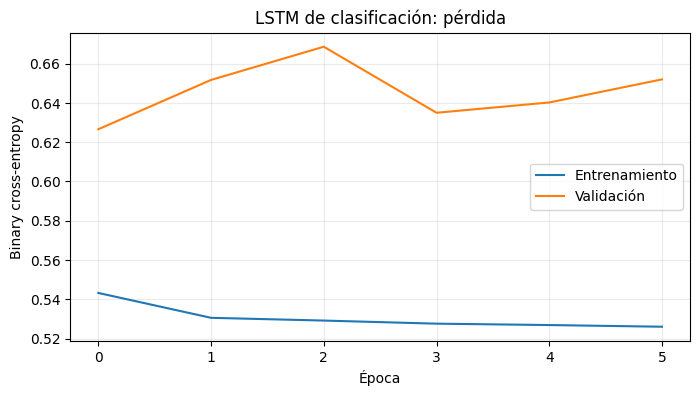

In [18]:
plt.figure(figsize=(8, 4))
plt.plot(hist_clf.history['loss'], label='Entrenamiento')
plt.plot(hist_clf.history['val_loss'], label='Validación')
plt.xlabel('Época')
plt.ylabel('Binary cross-entropy')
plt.title('LSTM de clasificación: pérdida')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 16. Seleccionar el umbral de clasificación con validación

La salida sigmoid no se convierte necesariamente en clase usando 0.5. Como la clase positiva puede ser poco frecuente, evaluamos distintos umbrales con el bloque de validación y seleccionamos el que obtiene el mejor F1.

**El test no se utiliza para elegir el umbral.**

In [19]:
def obtener_probabilidades(modelo, indices):
    generador = GeneradorVentanas(
        indices, BATCH_SIZE, tarea='clf', shuffle=False
    )
    return modelo.predict(generador, verbose=1).ravel()

prob_val = obtener_probabilidades(modelo_clf, idx_val)
y_val = y_clf_original[idx_val]

filas_umbrales = []
for umbral in np.arange(0.05, 0.96, 0.01):
    pred = (prob_val >= umbral).astype('int8')
    filas_umbrales.append({
        'umbral': float(umbral),
        'precision': precision_score(y_val, pred, zero_division=0),
        'recall': recall_score(y_val, pred, zero_division=0),
        'f1': f1_score(y_val, pred, zero_division=0)
    })

tabla_umbrales = pd.DataFrame(filas_umbrales).sort_values(
    ['f1', 'recall'], ascending=[False, False]
)
UMBRAL_FINAL = float(tabla_umbrales.iloc[0]['umbral'])

display(tabla_umbrales.head(10))
print('Umbral seleccionado:', UMBRAL_FINAL)

800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step


,umbral,precision,recall,f1
77,0.82,0.386254,0.583084,0.464685
78,0.83,0.393714,0.566707,0.464631
75,0.80,0.372988,0.615538,0.464506
76,0.81,0.378984,0.599660,0.464442
79,0.84,0.401624,0.548133,0.463578
80,0.85,0.411377,0.530058,0.463237
74,0.79,0.365729,0.628320,0.462341
81,0.86,0.421648,0.509986,0.461629
73,0.78,0.359163,0.639205,0.459908
82,0.87,0.432188,0.487517,0.458189


Umbral seleccionado: 0.8200000000000002


## 17. Reentrenar con todos los datos anteriores a 2025

Ya utilizamos validación para seleccionar las mejores épocas y el umbral. Ahora entrenamos cada modelo desde cero con todos los objetivos anteriores a 2025 (entrenamiento + validación), durante el número de épocas seleccionado.

El periodo desde 2025 permanece separado y se usa únicamente para la evaluación final.

In [20]:
gen_train_final_reg = GeneradorVentanas(
    idx_train_final, BATCH_SIZE, tarea='reg', shuffle=True
)
gen_train_final_clf = GeneradorVentanas(
    idx_train_final, BATCH_SIZE, tarea='clf',
    shuffle=True, pesos=pesos_muestra
)

modelo_reg_final = construir_lstm_regresion()
modelo_reg_final.fit(
    gen_train_final_reg,
    epochs=MEJOR_EPOCA_REG,
    verbose=1
)

modelo_clf_final = construir_lstm_clasificacion()
modelo_clf_final.fit(
    gen_train_final_clf,
    epochs=MEJOR_EPOCA_CLF,
    verbose=1
)

Epoch 1/4


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


  12/4365 ━━━━━━━━━━━━━━━━━━━━ 1:05 15ms/step - loss: 0.8970 - mae: 0.3221

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

  24/4365 ━━━━━━━━━━━━━━━━━━━━ 1:05 15ms/step - loss: 0.9804 - mae: 0.3388

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

... (2,191 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

4365/4365 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.1154 - mae: 0.2795

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

4365/4365 ━━━━━━━━━━━━━━━━━━━━ 64s 15ms/step - loss: 1.2763 - mae: 0.2824
4365/4365 ━━━━━━━━━━━━━━━━━━━━ 68s 15ms/step - loss: 0.5962 - pr_auc: 0.2513 - precision: 0.0908 - recall: 0.8418


## 18. Evaluar los modelos en el conjunto de prueba

**Regresión:** calculamos MAE, RMSE y R². Antes de calcular las métricas, convertimos la salida escalada a la cantidad original de homicidios y limitamos predicciones negativas a cero.

**Clasificación:** calculamos precision, recall, F1, PR-AUC y matriz de confusión. La clase positiva es `1` (hubo homicidios).

In [21]:
# Predicción de regresión
gen_test_reg = GeneradorVentanas(
    idx_test, BATCH_SIZE, tarea='reg', shuffle=False
)
pred_reg_escalada = modelo_reg_final.predict(gen_test_reg, verbose=1)
pred_reg = escalador_y.inverse_transform(pred_reg_escalada).ravel()
pred_reg = np.maximum(pred_reg, 0)
y_test_reg = y_reg_original[idx_test]

metricas_reg = {
    'MAE': float(mean_absolute_error(y_test_reg, pred_reg)),
    'RMSE': float(np.sqrt(mean_squared_error(y_test_reg, pred_reg))),
    'R2': float(r2_score(y_test_reg, pred_reg))
}
print('Métricas LSTM regresión:', metricas_reg)

# Predicción de clasificación
gen_test_clf = GeneradorVentanas(
    idx_test, BATCH_SIZE, tarea='clf', shuffle=False
)
prob_test = modelo_clf_final.predict(gen_test_clf, verbose=1).ravel()
pred_clf = (prob_test >= UMBRAL_FINAL).astype('int8')
y_test_clf = y_clf_original[idx_test]

metricas_clf = {
    'Accuracy': float(accuracy_score(y_test_clf, pred_clf)),
    'Precision_positiva': float(precision_score(y_test_clf, pred_clf, zero_division=0)),
    'Recall_positiva': float(recall_score(y_test_clf, pred_clf, zero_division=0)),
    'F1_positiva': float(f1_score(y_test_clf, pred_clf, zero_division=0)),
    'PR_AUC': float(average_precision_score(y_test_clf, prob_test))
}
print('Métricas LSTM clasificación:', metricas_clf)

print('Matriz de confusión [ [TN, FP], [FN, TP] ]:')
print(confusion_matrix(y_test_clf, pred_clf, labels=[0, 1]))
print(classification_report(y_test_clf, pred_clf, zero_division=0))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


 22/665 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

 54/665 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

 92/665 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step

... (30 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

659/665 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

665/665 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step
Métricas LSTM regresión: {'MAE': 0.21354395151138306, 'RMSE': 0.5729356300221119, 'R2': 0.20109212398529053}
665/665 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step
Métricas LSTM clasificación: {'Accuracy': 0.8041235902255639, 'Precision_positiva': 0.3279260586626426, 'Recall_positiva': 0.74176, 'F1_positiva': 0.4547921912298486, 'PR_AUC': 0.44848727169598795}
Matriz de confusión [ [TN, FP], [FN, TP] ]:
[[61493 14252]
 [ 2421  6954]]
              precision    recall  f1-score   support

           0       0.96      0.81      0.88     75745
           1       0.33      0.74      0.45      9375

    accuracy                           0.80     85120
   macro avg       0.65      0.78      0.67     85120
weighted avg       0.89      0.80      0.83     85120



## 19. Revisar gráficamente los resultados

Los gráficos permiten observar el comportamiento de la pérdida durante el entrenamiento y los errores de clasificación. Recuerda que Accuracy puede ser engañosa si hay muchos más días sin homicidios que con homicidios; presta especial atención a precision, recall, F1 y PR-AUC.

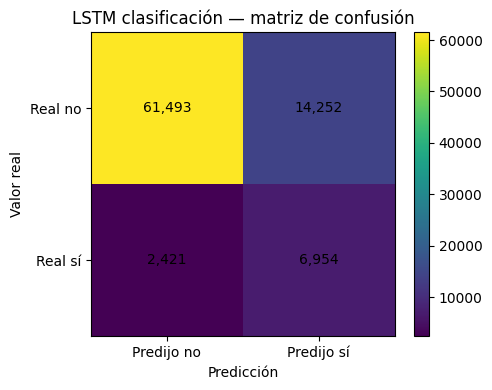

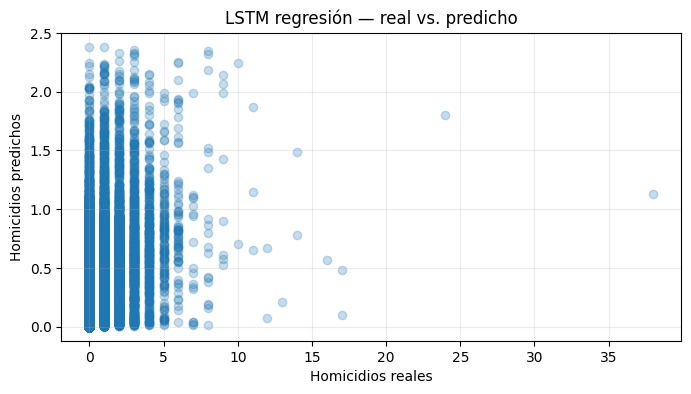

In [22]:
cm = confusion_matrix(y_test_clf, pred_clf, labels=[0, 1])

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm)
for (i, j), valor in np.ndenumerate(cm):
    ax.text(j, i, f'{valor:,}', ha='center', va='center')
ax.set_xticks([0, 1], labels=['Predijo no', 'Predijo sí'])
ax.set_yticks([0, 1], labels=['Real no', 'Real sí'])
ax.set_title('LSTM clasificación — matriz de confusión')
ax.set_xlabel('Predicción')
ax.set_ylabel('Valor real')
fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.scatter(y_test_reg, pred_reg, alpha=0.25)
plt.xlabel('Homicidios reales')
plt.ylabel('Homicidios predichos')
plt.title('LSTM regresión — real vs. predicho')
plt.grid(alpha=0.25)
plt.show()

## 20. Guardar modelos, escaladores y resultados

Guardamos los dos modelos entrenados, los escaladores y las predicciones del periodo de prueba en Google Drive. Así puedes volver a cargarlos sin entrenar desde cero.

In [23]:
# Tabla con valores reales y predicciones para las mismas fechas objetivo.
predicciones = DF_DIA.iloc[idx_test][
    ['codigo_provincia', 'codigo_distrito', 'fecha',
     'total_homicidios', 'hubo_homicidios']
].copy()

predicciones['prediccion_regresion_lstm'] = pred_reg
predicciones['puntuacion_clasificacion_lstm'] = prob_test
predicciones['prediccion_clasificacion_lstm'] = pred_clf

predicciones.to_csv(
    CARPETA_RESULTADOS / 'predicciones_lstm_test.csv',
    index=False
)

modelo_reg_final.save(CARPETA_RESULTADOS / 'lstm_regresion.keras')
modelo_clf_final.save(CARPETA_RESULTADOS / 'lstm_clasificacion.keras')

import joblib
joblib.dump(escalador_x, CARPETA_RESULTADOS / 'escalador_entradas.joblib')
joblib.dump(escalador_y, CARPETA_RESULTADOS / 'escalador_objetivo_regresion.joblib')

pd.DataFrame([metricas_reg]).to_csv(
    CARPETA_RESULTADOS / 'metricas_lstm_regresion.csv', index=False
)
pd.DataFrame([metricas_clf]).to_csv(
    CARPETA_RESULTADOS / 'metricas_lstm_clasificacion.csv', index=False
)

configuracion = {
    'modelo': 'LSTM',
    'ventana_dias': VENTANA,
    'fecha_inicio_validacion': str(FECHA_VALIDACION.date()),
    'fecha_inicio_test': str(FECHA_TEST.date()),
    'ventanas_subentrenamiento': int(len(idx_sub)),
    'ventanas_validacion': int(len(idx_val)),
    'ventanas_entrenamiento_final': int(len(idx_train_final)),
    'ventanas_test': int(len(idx_test)),
    'batch_size': BATCH_SIZE,
    'mejor_epoca_regresion': MEJOR_EPOCA_REG,
    'mejor_epoca_clasificacion': MEJOR_EPOCA_CLF,
    'umbral_clasificacion': UMBRAL_FINAL,
    'metricas_regresion_test': metricas_reg,
    'metricas_clasificacion_test': metricas_clf
}
(CARPETA_RESULTADOS / 'configuracion_lstm.json').write_text(
    json.dumps(configuracion, ensure_ascii=False, indent=2),
    encoding='utf-8'
)

print('Archivos guardados en:', CARPETA_RESULTADOS)
display(predicciones.head(10))

Archivos guardados en: /content/drive/MyDrive/ModelLOA/Resultados/LSTM_Semana6


,codigo_provincia,codigo_distrito,fecha,total_homicidios,hubo_homicidios,prediccion_regresion_lstm,puntuacion_clasificacion_lstm,prediccion_clasificacion_lstm
4018,01,01D01,2025-01-01,0.0,0,0.027382,0.468041,0
4019,01,01D01,2025-01-02,0.0,0,0.025144,0.431100,0
4020,01,01D01,2025-01-03,0.0,0,0.028232,0.472092,0
4021,01,01D01,2025-01-04,0.0,0,0.034949,0.539742,0
4022,01,01D01,2025-01-05,0.0,0,0.033616,0.550908,0
4023,01,01D01,2025-01-06,0.0,0,0.024984,0.478621,0
4024,01,01D01,2025-01-07,0.0,0,0.022025,0.434161,0
4025,01,01D01,2025-01-08,0.0,0,0.022789,0.416224,0
4026,01,01D01,2025-01-09,0.0,0,0.025338,0.436444,0
4027,01,01D01,2025-01-10,0.0,0,0.027381,0.472074,0


## 21. Interpretación y advertencias

Al terminar, revisa:

- **Regresión — MAE:** error absoluto medio en número de homicidios por registro diario provincia-distrito. Cuanto menor, mejor.
- **Clasificación — Precision:** de los días que el modelo marcó como positivos, cuántos realmente lo fueron.
- **Clasificación — Recall:** de todos los días positivos reales, cuántos detectó.
- **F1:** equilibrio entre precision y recall.
- **PR-AUC:** capacidad de ordenar correctamente la clase positiva, útil cuando hay desequilibrio de clases.

### Limitaciones metodológicas que debes tener presentes

1. Los días sin fila en el CSV no se interpretan automáticamente como cero; se descartan las ventanas que cruzan esos huecos.
2. La evaluación mide predicción diaria por provincia-distrito, no por franja horaria.
3. El modelo no demuestra causalidad. Las relaciones encontradas son patrones predictivos.
4. No se debe afirmar que LSTM es mejor que otro algoritmo sin comparar ambos sobre exactamente las mismas fechas objetivo y la misma unidad de análisis.
5. Si el número de ventanas válidas es muy bajo, revisa la continuidad y cobertura de los datos antes de interpretar los resultados.